# Parte Comum — Análise Exploratória de Dados (EDA)

Dataset: **Obesity** (`data/parte_comum/ObesityDataSet_raw_and_data_sinthetic.csv`)

## 0. Carregar o Dataset

In [1]:
# [IA] Google Gemini – carregamento do dataset e configuração inicial
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

caminho = "../../data/parte_comum/ObesityDataSet_raw_and_data_sinthetic.csv"
df = pd.read_csv(caminho)

print("Dataset carregado com sucesso!")
df.head()

Dataset carregado com sucesso!


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


### Dicionário de Variáveis (Legenda das Colunas)

Para facilitar a leitura das tabelas e gráficos, abaixo está a descrição de todas as 17 colunas do dataset *Obesity* (UCI ML Repository):

| Coluna | Significado | Tipo | Escala / Valores possíveis |
|---|---|---|---|
| `Gender` | Sexo biológico | Categórica (binária) | `Female`, `Male` |
| `Age` | Idade | Numérica (contínua) | Anos (14 a 61) |
| `Height` | Altura | Numérica (contínua) | Metros (1,45 a 1,98) |
| `Weight` | Peso corporal | Numérica (contínua) | Quilogramas (39 a 173) |
| `family_history_with_overweight` | Histórico familiar de sobrepeso/obesidade | Categórica (binária) | `yes`, `no` |
| `FAVC` | Consumo frequente de alimentos altamente calóricos (*Frequent consumption of high caloric food*) | Categórica (binária) | `yes`, `no` |
| `FCVC` | Frequência de consumo de vegetais nas refeições (*Frequency of consumption of vegetables*) | Numérica / Ordinal | 1 (Nunca) a 3 (Sempre) |
| `NCP` | Número de refeições principais por dia (*Number of main meals*) | Numérica / Ordinal | 1 a 4 refeições |
| `CAEC` | Consumo de alimentos entre as refeições (*Consumption of food between meals*) | Categórica (ordinal) | `no`, `Sometimes`, `Frequently`, `Always` |
| `SMOKE` | Hábito de fumar | Categórica (binária) | `yes`, `no` |
| `CH2O` | Consumo diário de água (*Consumption of water daily*) | Numérica / Ordinal | 1 (< 1L), 2 (1–2L), 3 (> 2L) |
| `SCC` | Monitoramento do consumo de calorias (*Calories consumption monitoring*) | Categórica (binária) | `yes`, `no` |
| `FAF` | Frequência de atividade física semanal (*Physical activity frequency*) | Numérica / Ordinal | 0 (Nenhuma) a 3 (4–5+ dias/sem.) |
| `TUE` | Tempo diário usando dispositivos tecnológicos (*Time using technology devices*) | Numérica / Ordinal | 0 (0–2h), 1 (3–5h), 2 (> 5h) |
| `CALC` | Consumo de álcool (*Consumption of alcohol*) | Categórica (ordinal) | `no`, `Sometimes`, `Frequently`, `Always` |
| `MTRANS` | Meio de transporte habitual (*Transportation used*) | Categórica (nominal) | `Automobile`, `Motorbike`, `Bike`, `Public_Transportation`, `Walking` |
| `NObeyesdad` | Nível de obesidade (variável alvo / classe real) | Categórica (ordinal, 7 classes) | `Insufficient_Weight`, `Normal_Weight`, `Overweight_Level_I`, `Overweight_Level_II`, `Obesity_Type_I`, `Obesity_Type_II`, `Obesity_Type_III` |

## 1. Análise Exploratória de Dados (EDA)

### 1.1 Estrutural

In [2]:
# [IA] Google Gemini – inspeção estrutural, valores ausentes e duplicatas
print(f"Dimensões: {df.shape[0]} linhas e {df.shape[1]} colunas\n")

print("--- Estrutura e tipos de variáveis ---")
df.info()

print("\n--- Valores ausentes por coluna ---")
print(df.isnull().sum())

print(f"\nLinhas duplicadas: {df.duplicated().sum()}")

Dimensões: 2111 linhas e 17 colunas

--- Estrutura e tipos de variáveis ---
<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   str    
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  CH2O                            2111 non-null   float64
 11  SCC                           

**Nota autoral sobre estrutura e duplicatas:**  
Foi decidido por remover as linhas duplicadas por parte do grupo devido à baixa probabilidade de duas pessoas diferentes responderem exatamente igual a 17 perguntas, podendo configurar como envios duplicados de formulário. Além disso, como o número de linhas duplicadas é pouco, não perderemos volume relevante.

In [3]:
# [IA] Google Gemini – inspeção e remoção de linhas duplicadas
duplicadas = df[df.duplicated(keep=False)].sort_values(by=["Age", "Height", "Weight"])
display(duplicadas.head(10))

df = df.drop_duplicates().reset_index(drop=True)
print(f"Novo formato após remoção das duplicadas: {df.shape[0]} linhas e {df.shape[1]} colunas")

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
295,Female,16.0,1.66,58.0,no,no,2.0,1.0,Sometimes,no,1.0,no,0.0,1.0,no,Walking,Normal_Weight
309,Female,16.0,1.66,58.0,no,no,2.0,1.0,Sometimes,no,1.0,no,0.0,1.0,no,Walking,Normal_Weight
282,Female,18.0,1.62,55.0,yes,yes,2.0,3.0,Frequently,no,1.0,no,1.0,1.0,no,Public_Transportation,Normal_Weight
460,Female,18.0,1.62,55.0,yes,yes,2.0,3.0,Frequently,no,1.0,no,1.0,1.0,no,Public_Transportation,Normal_Weight
443,Male,18.0,1.72,53.0,yes,yes,2.0,3.0,Sometimes,no,2.0,no,0.0,2.0,Sometimes,Public_Transportation,Insufficient_Weight
496,Male,18.0,1.72,53.0,yes,yes,2.0,3.0,Sometimes,no,2.0,no,0.0,2.0,Sometimes,Public_Transportation,Insufficient_Weight
97,Female,21.0,1.52,42.0,no,no,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
98,Female,21.0,1.52,42.0,no,no,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
523,Female,21.0,1.52,42.0,no,yes,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
527,Female,21.0,1.52,42.0,no,yes,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight


Novo formato após remoção das duplicadas: 2087 linhas e 17 colunas


### 1.2 Distribucional

#### Tabelas de distribuição

In [4]:
# [IA] Google Gemini – estatísticas descritivas (numéricas) e tabelas de frequência (categóricas)
colunas_num = df.select_dtypes(include=[np.number]).columns.tolist()
colunas_cat = df.select_dtypes(exclude=[np.number]).columns.tolist()

print("--- Resumo Estatístico (Variáveis Numéricas) ---")
display(df[colunas_num].describe().T.round(2))

print("\n--- Frequência (Variáveis Categóricas) ---")
for col in colunas_cat:
    print(f"\nColuna: {col}")
    tabela_freq = pd.DataFrame({
        "Contagem": df[col].value_counts(dropna=False),
        "Proporção (%)": (df[col].value_counts(normalize=True, dropna=False) * 100).round(2)
    })
    display(tabela_freq)

--- Resumo Estatístico (Variáveis Numéricas) ---


,count,mean,std,min,25%,50%,75%,max
Age,2087.0,24.35,6.37,14.00,19.92,22.85,26.00,61.00
Height,2087.0,1.70,0.09,1.45,1.63,1.70,1.77,1.98
Weight,2087.0,86.86,26.19,39.00,66.00,83.10,108.02,173.00
FCVC,2087.0,2.42,0.53,1.00,2.00,2.40,3.00,3.00
NCP,2087.0,2.70,0.76,1.00,2.70,3.00,3.00,4.00
CH2O,2087.0,2.00,0.61,1.00,1.59,2.00,2.47,3.00
FAF,2087.0,1.01,0.85,0.00,0.12,1.00,1.68,3.00
TUE,2087.0,0.66,0.61,0.00,0.00,0.63,1.00,2.00



--- Frequência (Variáveis Categóricas) ---

Coluna: Gender


,Contagem,Proporção (%)
Gender,,
Male,1052,50.41
Female,1035,49.59



Coluna: family_history_with_overweight


,Contagem,Proporção (%)
family_history_with_overweight,,
yes,1722,82.51
no,365,17.49


... (10 outputs left out)


Coluna: MTRANS


,Contagem,Proporção (%)
MTRANS,,
Public_Transportation,1558,74.65
Automobile,456,21.85
Walking,55,2.64
Motorbike,11,0.53
Bike,7,0.34



Coluna: NObeyesdad


,Contagem,Proporção (%)
NObeyesdad,,
Obesity_Type_I,351,16.82
Obesity_Type_III,324,15.52
Obesity_Type_II,297,14.23
Overweight_Level_II,290,13.90
Normal_Weight,282,13.51
Overweight_Level_I,276,13.22
Insufficient_Weight,267,12.79


#### Valores nao inteiros nas variaveis numericas

In [5]:
# [IA] Claude Code - proporcao de valores nao inteiros em cada variavel numerica
nao_inteiros = (df[colunas_num] % 1 != 0).mean().mul(100).round(1)
display(nao_inteiros.rename("% de valores nao inteiros").to_frame())

,% de valores nao inteiros
Age,65.9
Height,100.0
Weight,69.6
FCVC,39.6
NCP,30.7
CH2O,61.8
FAF,57.9
TUE,55.2


**Nota sobre a qualidade dos dados**

As variaveis `FCVC`, `NCP`, `CH2O`, `FAF` e `TUE` vem de perguntas de questionario com respostas inteiras (por exemplo, numero de refeicoes principais de 1 a 4), mas entre 30,7% e 61,8% dos valores nao sao inteiros. `Age` e `Weight` tambem tem muitos valores quebrados (65,9% e 69,6%). Isso e consistente com a informacao do UCI de que cerca de 77% do dataset foi gerado sinteticamente com SMOTE, que cria registros novos por interpolacao entre registros existentes. Mantivemos essas escalas como numericas no K-Means, lembrando que os valores intermediarios nao correspondem a respostas reais. `Height` tem 100% de valores nao inteiros por ser medida em metros, entao nao entra nessa leitura.

#### Gráficos de distribuição

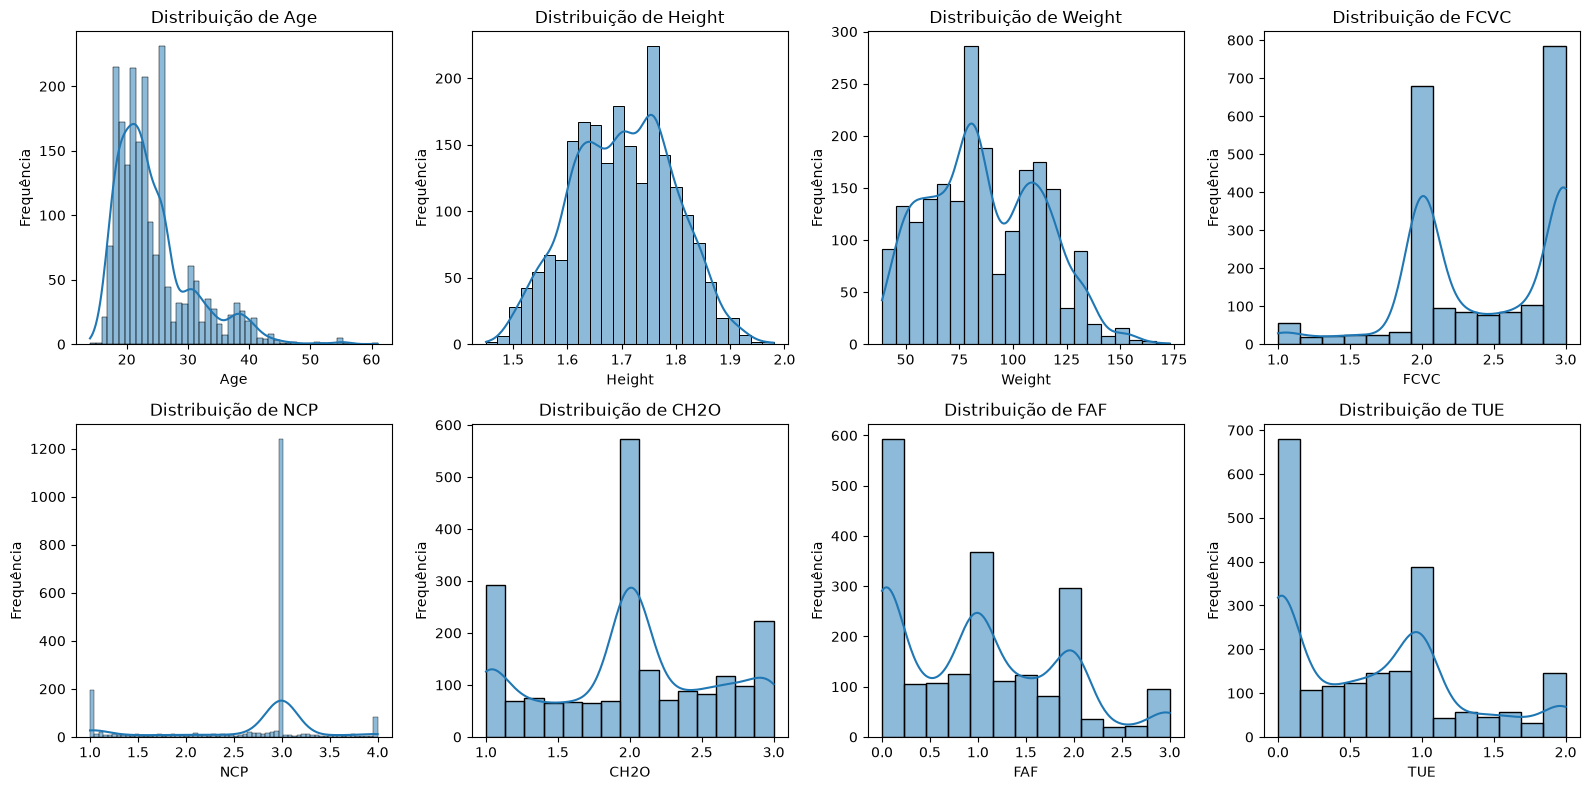

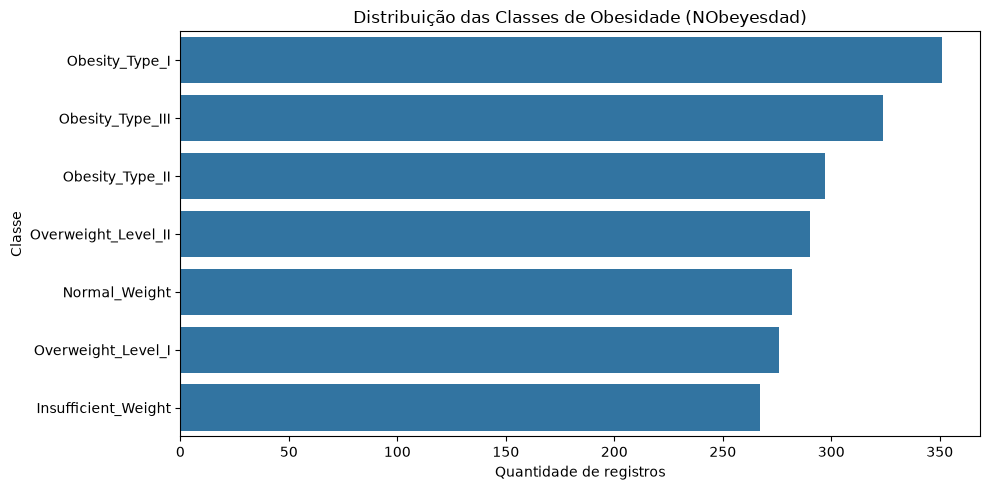

In [6]:
# [IA] Google Gemini – histogramas com KDE para variáveis numéricas e gráfico de barras da classe alvo
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(colunas_num):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f"Distribuição de {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequência")

plt.tight_layout()
plt.show()

# Distribuição da variável alvo (NObeyesdad)
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y="NObeyesdad", order=df["NObeyesdad"].value_counts().index)
plt.title("Distribuição das Classes de Obesidade (NObeyesdad)")
plt.xlabel("Quantidade de registros")
plt.ylabel("Classe")
plt.tight_layout()
plt.show()

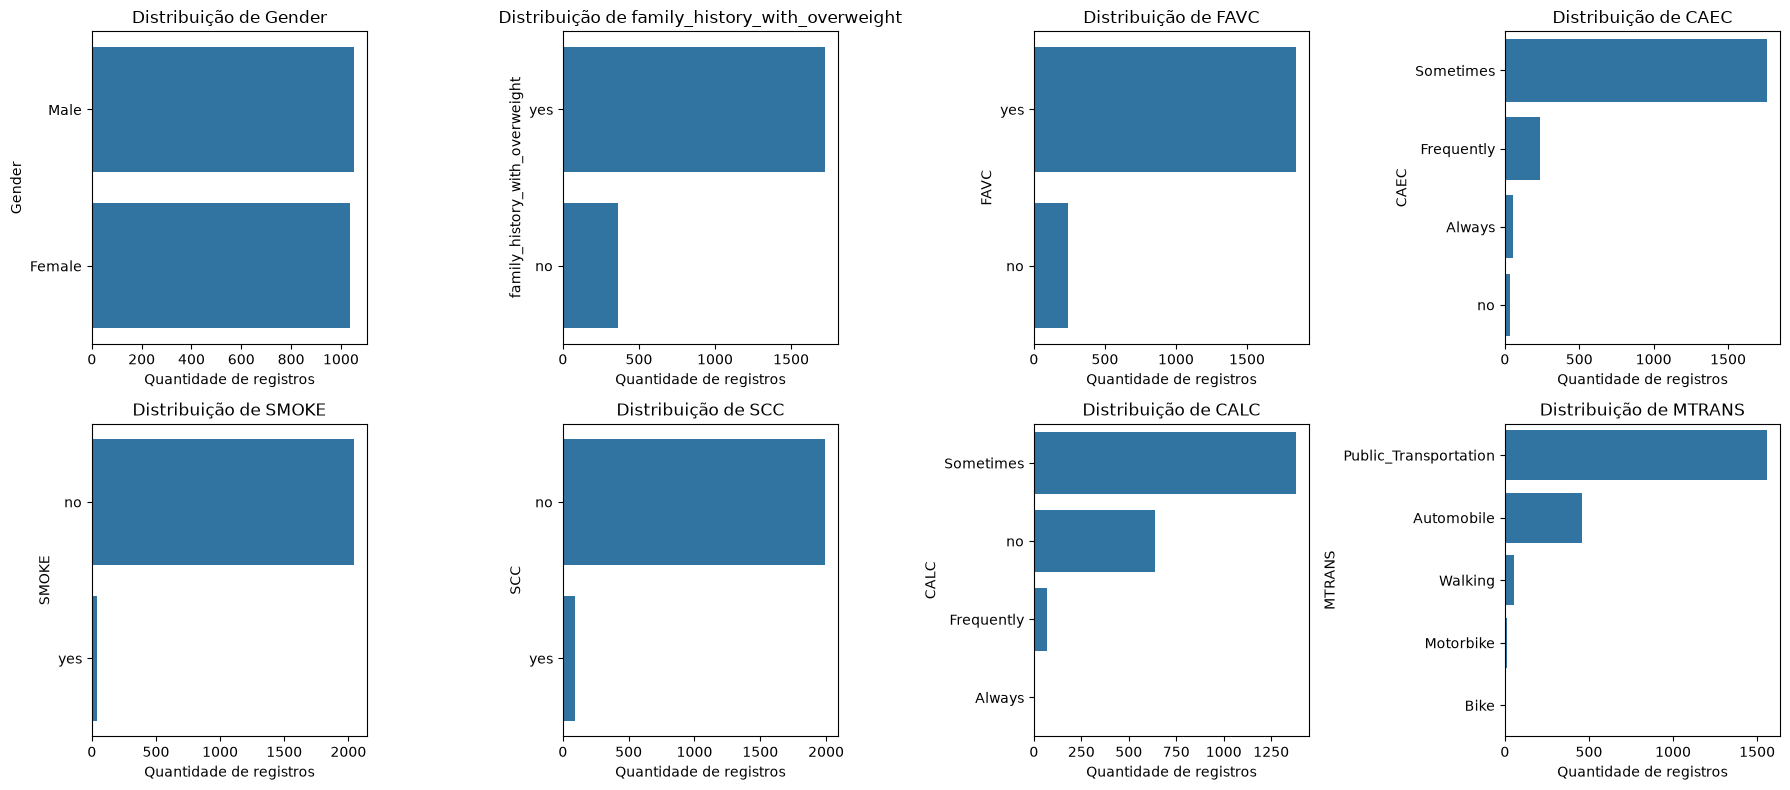

In [7]:
# [IA] GitHub Copilot – extensão dos gráficos de contagem (countplot) para todas as demais variáveis categóricas
colunas_cat_sem_alvo = [c for c in colunas_cat if c != "NObeyesdad"]

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(colunas_cat_sem_alvo):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, ax=axes[i])
    axes[i].set_title(f"Distribuição de {col}")
    axes[i].set_xlabel("Quantidade de registros")
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

**Nota sobre as distribuicoes**

* `Age` e concentrada em jovens (metade dos registros entre 19,9 e 26 anos, mediana 22,85) e tem cauda longa a direita ate 61 anos.
* `Height` e aproximadamente simetrica em torno de 1,70 m. `Weight` vai de 39 a 173 kg e nao tem um unico pico, o que combina com classes que vao de abaixo do peso ate obesidade tipo III.
* `FCVC`, `CH2O`, `FAF` e `TUE` tem picos nos valores inteiros e valores espalhados entre eles, efeito dos dados sinteticos. `NCP` e muito concentrada em 3 refeicoes.
* Nas categoricas, varias variaveis sao muito desbalanceadas (`SMOKE` com 97,9% de nao, `SCC` com 95,4% de nao, `FAVC` com 88,4% de sim, `family_history_with_overweight` com 82,5% de sim e `CAEC` com 84,4% de Sometimes). `CALC` tem a categoria Always com um unico registro e `MTRANS` tem Bike (7) e Motorbike (11) com poucos casos, entao comparacoes nessas categorias raras devem ser lidas com cautela.
* `Gender` e equilibrado (50,4% de homens) e as 7 classes de `NObeyesdad` tambem (entre 12,8% e 16,8% cada), o que e pouco comum em dados reais e e mais um sinal do balanceamento feito na geracao sintetica.

### 1.3 Relacional

#### Correlação entre variáveis numéricas

--- Teste de Normalidade (Shapiro-Wilk) ---


,Variável,Estatística W,p-valor,"Normal (α = 0,05)?"
0,Age,0.8679,8.448e-39,Não
1,Height,0.9934,5.135e-08,Não
2,Weight,0.9769,7.270e-18,Não
3,FCVC,0.8456,4.380e-41,Não
4,NCP,0.7391,2.821e-49,Não
5,CH2O,0.9350,2.930e-29,Não
6,FAF,0.9152,1.128e-32,Não
7,TUE,0.8887,2.289e-36,Não


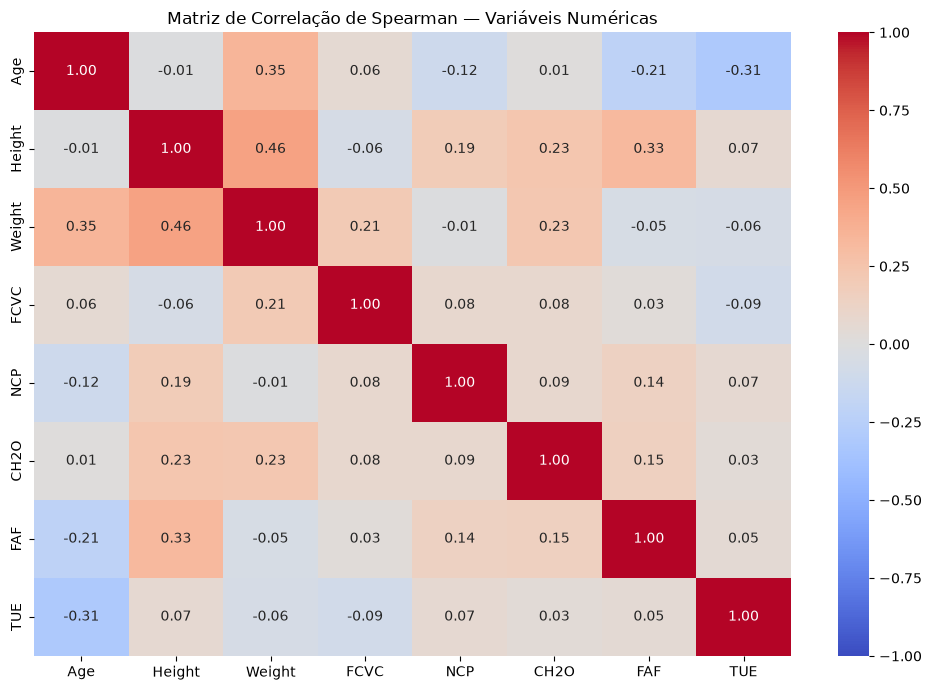

In [8]:
# [IA] Google Gemini – matriz de correlação das variáveis numéricas
# [IA] GitHub Copilot – teste de normalidade (Shapiro-Wilk)
# [IA] Claude Code – troca para a correlação de Spearman, indicada porque o Shapiro-Wilk rejeitou a normalidade
from scipy.stats import shapiro

# 1. Teste de normalidade de Shapiro-Wilk para cada variável numérica
resultados_norm = []
for col in colunas_num:
    stat, p_val = shapiro(df[col])
    resultados_norm.append({
        "Variável": col,
        "Estatística W": round(stat, 4),
        "p-valor": f"{p_val:.3e}",
        "Normal (α = 0,05)?": "Sim" if p_val >= 0.05 else "Não",
    })

print("--- Teste de Normalidade (Shapiro-Wilk) ---")
display(pd.DataFrame(resultados_norm))

# 2. Matriz de correlação de Spearman
# Nenhuma variável passou no teste de normalidade, então usamos Spearman, que trabalha com a ordem
# dos valores e não supõe normalidade nem relação linear. A padronização não é necessária aqui,
# porque a correlação já não depende da escala das variáveis.
corr = df[colunas_num].corr(method="spearman")

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação de Spearman — Variáveis Numéricas")
plt.tight_layout()
plt.show()

**Nota sobre a normalidade e a correlação**

O teste de Shapiro-Wilk rejeitou a normalidade das 8 variáveis numéricas (p-valor menor que 0,05 em todas). Por isso usamos a correlação de **Spearman** em vez da de Pearson: Spearman compara a ordem dos valores, então não supõe normalidade nem relação linear, e é menos sensível a valores extremos.

As correlações entre as variáveis numéricas são fracas no geral. A maior é entre `Height` e `Weight` (0,46), esperada porque pessoas mais altas tendem a pesar mais. Depois aparecem `Age` e `Weight` (0,35, pessoas mais velhas tendem a pesar mais), `Height` e `FAF` (0,33) e `Age` e `TUE` (-0,31, pessoas mais velhas passam menos tempo usando dispositivos). Nenhum par passa de 0,5, então não há redundância forte que justifique retirar alguma variável antes do K-Means.

#### Variáveis numéricas × Classe Alvo (`NObeyesdad`)

--- Média das variáveis numéricas por classe ---


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
NObeyesdad,,,,,,,,
Insufficient_Weight,19.77,1.69,50.01,2.47,2.94,1.88,1.27,0.85
Normal_Weight,21.76,1.68,62.16,2.34,2.75,1.86,1.25,0.68
Obesity_Type_I,25.88,1.69,92.87,2.19,2.43,2.11,0.99,0.68
Obesity_Type_II,28.23,1.77,115.31,2.39,2.74,1.88,0.97,0.52
Obesity_Type_III,23.50,1.69,120.94,3.00,3.00,2.21,0.66,0.60
Overweight_Level_I,23.54,1.69,74.48,2.28,2.58,2.01,1.06,0.64
Overweight_Level_II,27.00,1.70,82.09,2.26,2.50,2.03,0.96,0.70


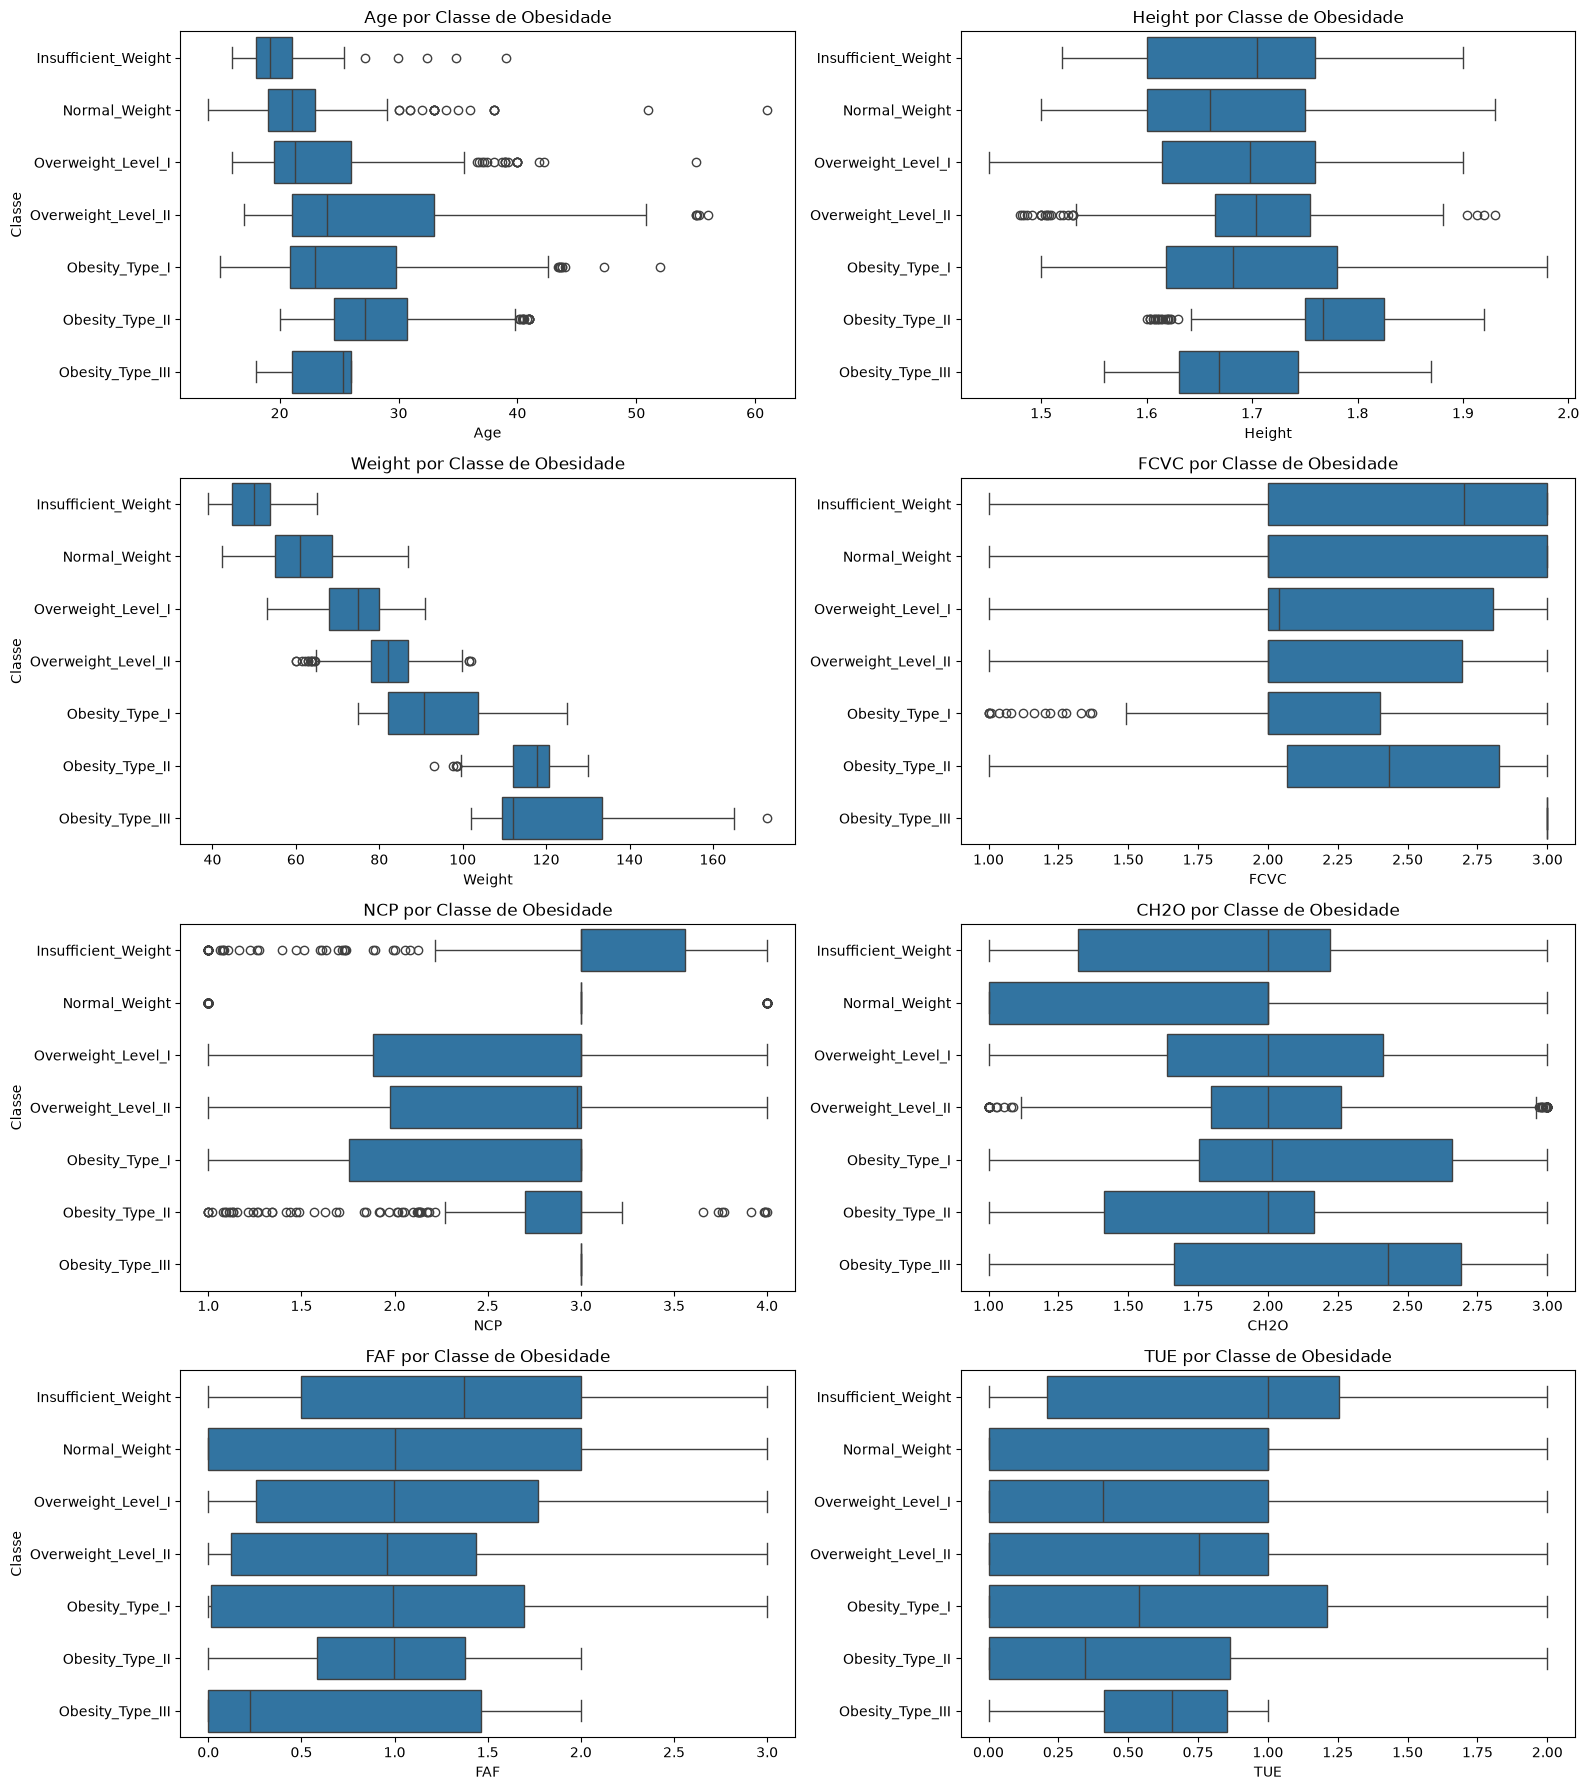

In [9]:
# [IA] Google Gemini – médias das variáveis numéricas por classe e boxplots por classe
# [IA] GitHub Copilot – extensão dos boxplots para cobrir todas as variáveis numéricas
print("--- Média das variáveis numéricas por classe ---")
display(df.groupby("NObeyesdad")[colunas_num].mean().round(2))

ordem_classes = [
    "Insufficient_Weight",
    "Normal_Weight",
    "Overweight_Level_I",
    "Overweight_Level_II",
    "Obesity_Type_I",
    "Obesity_Type_II",
    "Obesity_Type_III",
]

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(16, 18))
axes = axes.flatten()

for i, col in enumerate(colunas_num):
    sns.boxplot(data=df, y="NObeyesdad", x=col, order=ordem_classes, ax=axes[i])
    axes[i].set_title(f"{col} por Classe de Obesidade")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Classe" if i % 2 == 0 else "")

plt.tight_layout()
plt.show()

**Nota sobre as variaveis numericas por classe**

* `Weight` cresce de forma ordenada entre as classes (media de 50,0 kg em Insufficient_Weight ate 120,9 kg em Obesity_Type_III), o que e esperado porque as classes foram criadas a partir do IMC.
* `Height` e parecida entre as classes, com excecao de Obesity_Type_II, que tem altura maior (media de 1,77 m). Isso se explica pela composicao por sexo vista nas tabelas cruzadas abaixo.
* `Age` e maior em Overweight_Level_II e Obesity_Type_II (medias de 27,0 e 28,2 anos) e menor em Insufficient_Weight (19,8 anos).
* `FAF` (atividade fisica) cai de forma geral das classes mais leves para as mais pesadas (1,27 em Insufficient_Weight e 0,66 em Obesity_Type_III).
* Em Obesity_Type_III, `FCVC` e `NCP` valem 3 para todos os registros (o boxplot vira uma linha). Uma classe inteira com a mesma resposta em duas perguntas nao e esperado em dados reais e provavelmente e efeito da geracao sintetica. Isso ajuda a entender por que essa classe fica tao concentrada nos clusters do K-Means.

#### Variáveis categóricas × Classe Alvo (`NObeyesdad`)

In [10]:
# [IA] Google Gemini – tabelas cruzadas normalizadas por linha (categóricas x NObeyesdad)
for col in colunas_cat_sem_alvo:
    print(f"\n--- {col} x NObeyesdad (proporção por linha) ---")
    tabela = pd.crosstab(df[col], df["NObeyesdad"], normalize="index").round(3)
    display(tabela)


--- Gender x NObeyesdad (proporção por linha) ---


NObeyesdad,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
Gender,,,,,,,
Female,0.163,0.132,0.151,0.002,0.312,0.140,0.100
Male,0.093,0.138,0.185,0.280,0.001,0.125,0.178



--- family_history_with_overweight x NObeyesdad (proporção por linha) ---


NObeyesdad,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
family_history_with_overweight,,,,,,,
no,0.389,0.356,0.019,0.003,0.000,0.184,0.049
yes,0.073,0.088,0.200,0.172,0.188,0.121,0.158



--- FAVC x NObeyesdad (proporção por linha) ---


NObeyesdad,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
FAVC,,,,,,,
no,0.206,0.321,0.045,0.029,0.004,0.091,0.305
yes,0.118,0.111,0.184,0.157,0.175,0.138,0.117


... (6 outputs left out)


--- CALC x NObeyesdad (proporção por linha) ---


NObeyesdad,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
CALC,,,,,,,
Always,0.000,1.000,0.000,0.000,0.000,0.000,0.000
Frequently,0.014,0.257,0.200,0.029,0.000,0.229,0.271
Sometimes,0.108,0.115,0.125,0.162,0.234,0.152,0.104
no,0.184,0.164,0.259,0.112,0.002,0.079,0.201



--- MTRANS x NObeyesdad (proporção por linha) ---


NObeyesdad,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
MTRANS,,,,,,,
Automobile,0.101,0.096,0.241,0.208,0.002,0.145,0.206
Bike,0.000,0.571,0.000,0.143,0.000,0.286,0.000
Motorbike,0.000,0.545,0.273,0.000,0.000,0.091,0.091
Public_Transportation,0.138,0.126,0.151,0.128,0.207,0.127,0.121
Walking,0.109,0.564,0.036,0.018,0.000,0.164,0.109


**Nota sobre as variaveis categoricas por classe**

* `Gender` tem a relacao mais forte com a classe. Obesity_Type_II e quase so de homens (28% dos homens estao nessa classe, contra 0,2% das mulheres) e Obesity_Type_III e quase so de mulheres (31,2% das mulheres, contra 0,1% dos homens). Nessas duas classes, sexo e grau de obesidade ficam misturados.
* Quem nao tem historico familiar de sobrepeso (`family_history_with_overweight` igual a no) esta concentrado em Insufficient_Weight (38,9%) e Normal_Weight (35,6%), e nenhum caso aparece em Obesity_Type_III.
* `FAVC` igual a no (nao come alimentos caloricos com frequencia) aparece mais em Normal_Weight (32,1%) e Overweight_Level_II (30,5%).
* Em `CAEC`, quem come entre as refeicoes com frequencia (Frequently) esta mais em Insufficient_Weight (49,6%), e quem responde Sometimes, a maior parte da base, se espalha pelas classes de sobrepeso e obesidade.
* Em `MTRANS`, quem anda a pe esta mais em Normal_Weight (56,4%) e quem usa automovel aparece mais nas classes de sobrepeso e obesidade. Como Walking, Bike e Motorbike tem poucos registros, essas proporcoes sao instaveis.
* `SMOKE`, `SCC` e `CALC` tem categorias com poucos casos (44 fumantes e 1 registro com CALC Always), entao as proporcoes delas nao sao confiaveis para tirar conclusoes.

### 1.4 Outliers

#### Identificação quantitativa via IQR

In [11]:
# [IA] Google Gemini – cálculo quantitativo de outliers pelo método IQR
resumo_outliers = []

for col in colunas_num:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr

    qtd = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    pct = (qtd / len(df)) * 100

    resumo_outliers.append({
        "Variável": col,
        "Limite Inferior": round(lim_inf, 2),
        "Limite Superior": round(lim_sup, 2),
        "Qtd Outliers": qtd,
        "% Outliers": round(pct, 2)
    })

display(pd.DataFrame(resumo_outliers))

,Variável,Limite Inferior,Limite Superior,Qtd Outliers,% Outliers
0,Age,10.79,35.13,167,8.00
1,Height,1.42,1.98,1,0.05
2,Weight,2.98,171.04,1,0.05
3,FCVC,0.50,4.50,0,0.00
4,NCP,2.24,3.45,577,27.65
5,CH2O,0.28,3.78,0,0.00
6,FAF,-2.21,4.01,0,0.00
7,TUE,-1.50,2.50,0,0.00


#### Visualização dos outliers com Boxplots

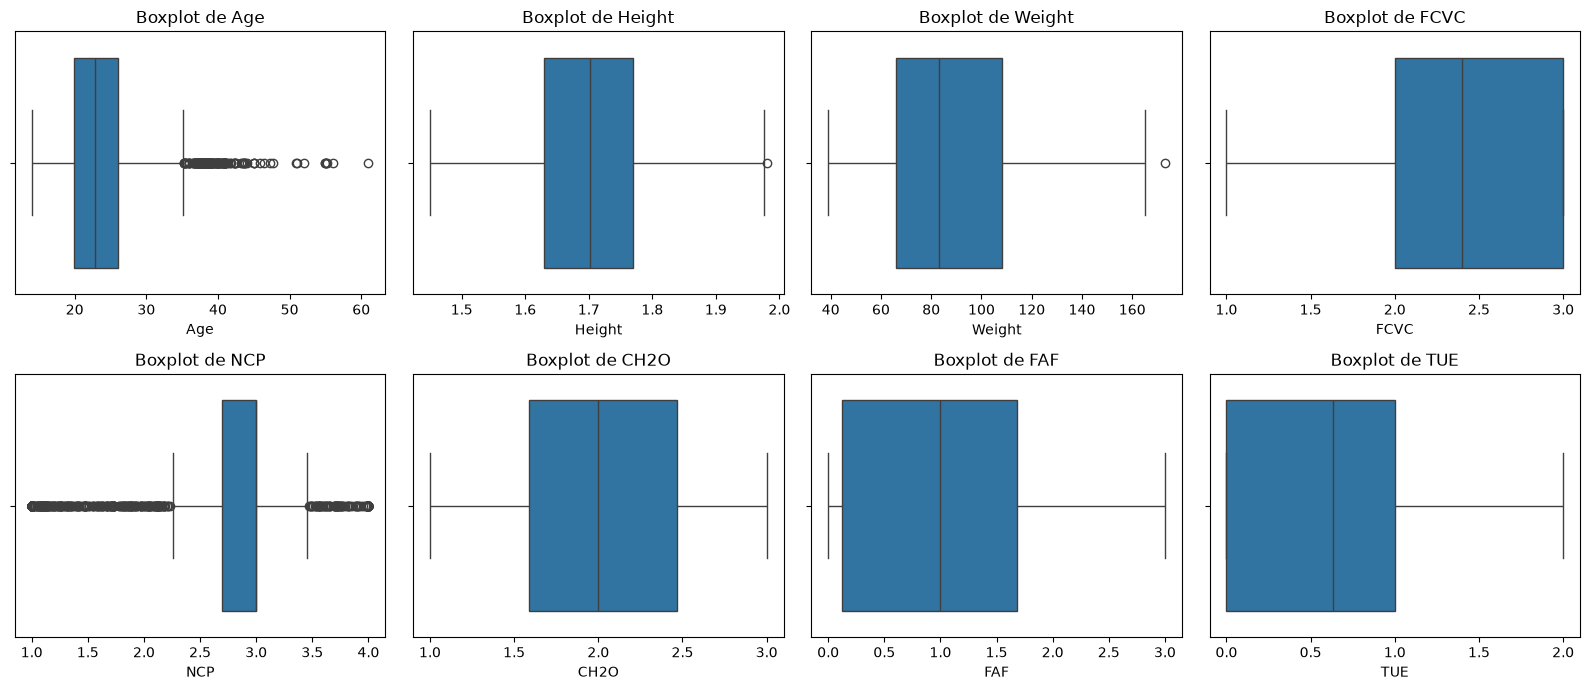

In [12]:
# [IA] Google Gemini – boxplots das variáveis numéricas para inspeção de outliers
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 7))
axes = axes.flatten()

for i, col in enumerate(colunas_num):
    sns.boxplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f"Boxplot de {col}")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

#### Distribuicao de NCP e limites do IQR

In [13]:
# [IA] Claude Code - contagem dos valores de NCP e limites do IQR para apoiar a discussao de outliers
q1_ncp, q3_ncp = df["NCP"].quantile([0.25, 0.75])
iqr_ncp = q3_ncp - q1_ncp
print(f"NCP (Q1 = {q1_ncp:.2f}, Q3 = {q3_ncp:.2f}, IQR = {iqr_ncp:.2f}, "
      f"limite inferior = {q1_ncp - 1.5 * iqr_ncp:.2f}, limite superior = {q3_ncp + 1.5 * iqr_ncp:.2f})")
display(df["NCP"].round().value_counts().sort_index().rename_axis("NCP (arredondado)").to_frame("Contagem"))

NCP (Q1 = 2.70, Q3 = 3.00, IQR = 0.30, limite inferior = 2.24, limite superior = 3.45)


,Contagem
NCP (arredondado),
1.0,296
2.0,176
3.0,1466
4.0,149


#### Discussão e Decisão sobre Outliers

* **Identificação:** A partir da tabela do método IQR e dos boxplots, as variáveis numéricas que apresentaram maior quantidade de outliers foram `NCP` e `Age`, com **27,65%** e **8,00%** dos registros fora dos limites, respectivamente. Já o resto das variáveis apresentaram 1 ou 0 valores extremos.

* **Avaliação no contexto do domínio:** Ao observar os valores extremos encontrados (por exemplo, idade como 60+), avaliamos que esses registros representam casos reais possíveis no contexto de obesidade, devido à variabilidade natural da população analisada e à possibilidade de ocorrência desses valores no cenário estudado, não sendo considerados inconsistências nos dados.

* **Caso do NCP.** O alto numero de outliers em `NCP` (577 registros, 27,65%) vem do proprio metodo do IQR. Como cerca de 70% das pessoas responderam 3 refeicoes principais, o primeiro e o terceiro quartil ficam muito proximos (2,70 e 3,00) e o IQR e de apenas 0,30, o que deixa os limites entre 2,24 e 3,45. Assim, quem respondeu 1, 2 ou 4 refeicoes vira outlier, mesmo sendo uma resposta valida da pergunta (que vai de 1 a 4). Esses valores nao sao erros e foram mantidos.

* **Height e Weight.** Os unicos valores fora dos limites sao a maior altura (1,98 m) e o maior peso (173 kg), ambos plausiveis para uma pessoa adulta, e o peso de 173 kg pertence a classe Obesity_Type_III, coerente com ela.

* **Decisão de tratamento:** Optamos por manter todos os registros. Essa escolha se justifica pois os valores identificados são plausíveis dentro do contexto do dataset e sua remoção poderia resultar na perda de informações relevantes sobre a população analisada, comprometendo a representatividade dos dados e, consequentemente, a formação dos clusters pelo K-Means.